# IMPLEMENTASI ALGORITMA K-NEAREST NEIGHBORS (KNN) PADA KLASIFIKASI RISIKO KESEHATAN IBU HAMIL

Notebook ini mengimplementasikan algoritma **K-Nearest Neighbors (KNN)** menggunakan dataset yang telah dibersihkan (`Maternal_Risk_Clean.csv`).

**Alur Pengerjaan:**
1. Import Library & Load Dataset
2. Stratified Train-Test Split (80:20)
3. Standarisasi Fitur dengan StandardScaler
4. Pelatihan Model KNN
5. Evaluasi Model pada Data Uji (Classification Report, Confusion Matrix, dan ROC-AUC)
6. Simulasi Prediksi Pasien Baru


---
## 1. Import Library & Load Dataset


### 1.1 Import Library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

sns.set_style('whitegrid')
plt.rcParams['font.size'] = 10

import warnings
warnings.filterwarnings('ignore')

print('Library berhasil di-import!')


Library berhasil di-import!


### 1.2 Load Dataset Bersih (`Maternal_Risk_Clean.csv`)


In [2]:
# Membaca dataset
df = pd.read_csv('Maternal_Risk_Clean.csv')
print(f'Dataset berhasil dimuat! Ukuran: {df.shape[0]} baris x {df.shape[1]} kolom')
df.head()


Dataset berhasil dimuat! Ukuran: 1168 baris x 12 kolom


### 1.3 Informasi Dataset & Encoding Target


In [3]:
# Info dataset
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1168 non-null   int64  
 1   Systolic BP             1168 non-null   float64
 2   Diastolic               1168 non-null   float64
 3   BS                      1168 non-null   float64
 4   Body Temp               1168 non-null   int64  
 5   BMI                     1168 non-null   float64
 6   Previous Complications  1168 non-null   int64  
 7   Preexisting Diabetes    1168 non-null   int64  
 8   Gestational Diabetes    1168 non-null   int64  
 9   Mental Health           1168 non-null   int64  
 10  Heart Rate              1168 non-null   float64
 11  Risk Level              1168 non-null   str    
dtypes: float64(5), int64(6), str(1)
memory usage: 109.6 KB


In [4]:
# Encoding target: Low -> 0, High -> 1
target_mapping = {'Low': 0, 'High': 1}
df['Risk_Level_Code'] = df['Risk Level'].map(target_mapping)

print('Distribusi target:')
print(df['Risk Level'].value_counts())
print()
print('Persentase:')
print((df['Risk Level'].value_counts(normalize=True) * 100).round(2))


Distribusi target:
Risk Level
Low     695
High    473
Name: count, dtype: int64

Persentase:
Risk Level
Low     59.5
High    40.5
Name: proportion, dtype: float64


---
## 2. Stratified Train-Test Split (80:20)

Pemisahan data menjadi data latih (80%) dan data uji (20%) dengan mempertahankan proporsi kelas target menggunakan parameter `stratify`.


In [5]:
# Memisahkan fitur dan target
feature_cols = [c for c in df.columns if c not in ['Risk Level', 'Risk_Level_Code']]
X = df[feature_cols].copy()
y = df['Risk_Level_Code'].copy()

print(f'Jumlah fitur: {len(feature_cols)}')
print('Daftar fitur:', feature_cols)


Jumlah fitur: 11
Daftar fitur: ['Age', 'Systolic BP', 'Diastolic', 'BS', 'Body Temp', 'BMI', 'Previous Complications', 'Preexisting Diabetes', 'Gestational Diabetes', 'Mental Health', 'Heart Rate']


In [6]:
# Split data train dan test (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f'Jumlah data latih : {len(X_train)} baris ({(len(X_train)/len(X)*100):.1f}%)')
print(f'Jumlah data uji   : {len(X_test)} baris ({(len(X_test)/len(X)*100):.1f}%)')
print()
print('Distribusi target pada data latih:')
print(y_train.value_counts())
print()
print('Distribusi target pada data uji:')
print(y_test.value_counts())


Jumlah data latih : 934 baris (80.0%)
Jumlah data uji   : 234 baris (20.0%)

Distribusi target pada data latih:
Risk_Level_Code
0    556
1    378
Name: count, dtype: int64

Distribusi target pada data uji:
Risk_Level_Code
0    139
1     95
Name: count, dtype: int64


---
## 3. Standarisasi Fitur Menggunakan StandardScaler

Algoritma KNN mengukur kedekatan data berdasarkan jarak matematis (Euclidean Distance). Oleh karena itu, seluruh fitur numerik distandarisasi menggunakan `StandardScaler` agar fitur dengan rentang nilai besar tidak mendominasi perhitungan jarak.


In [7]:
# Standarisasi fitur
scaler = StandardScaler()

# Fit hanya pada data latih untuk menghindari data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Standarisasi data berhasil dilakukan.')
print(f'Dimensi X_train_scaled: {X_train_scaled.shape}')
print(f'Dimensi X_test_scaled : {X_test_scaled.shape}')


Standarisasi data berhasil dilakukan.
Dimensi X_train_scaled: (934, 11)
Dimensi X_test_scaled : (234, 11)


---
## 4. Pelatihan Model K-Nearest Neighbors (KNN)

Model KNN dilatih menggunakan data latih yang telah distandarisasi dengan jumlah tetangga $k = 5$.


In [8]:
# Inisialisasi dan training model KNN
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_scaled, y_train)

print(f'Model KNN (k={k}) berhasil dilatih.')


Model KNN (k=5) berhasil dilatih.


---
## 5. Evaluasi Model pada Data Uji


In [9]:
# Prediksi pada data uji
y_pred = knn.predict(X_test_scaled)
y_prob = knn.predict_proba(X_test_scaled)[:, 1]

# Classification report
print('=== CLASSIFICATION REPORT ===')
print(classification_report(y_test, y_pred, target_names=['Low Risk', 'High Risk'], digits=4))


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Low Risk     0.9716    0.9856    0.9786       139
   High Risk     0.9785    0.9579    0.9681        95

    accuracy                         0.9744       234
   macro avg     0.9751    0.9718    0.9733       234
weighted avg     0.9744    0.9744    0.9743       234



True Negative  : 137
False Positive : 2
False Negative : 4
True Positive  : 91


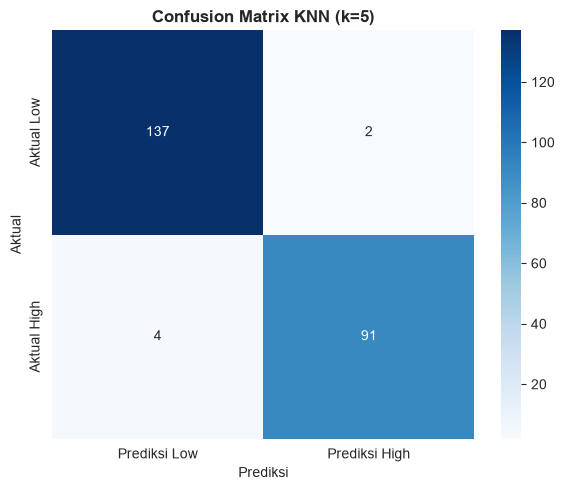

In [10]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Low', 'Prediksi High'],
            yticklabels=['Aktual Low', 'Aktual High'])
plt.title(f'Confusion Matrix KNN (k={k})', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

print(f'True Negative  : {cm[0, 0]}')
print(f'False Positive : {cm[0, 1]}')
print(f'False Negative : {cm[1, 0]}')
print(f'True Positive  : {cm[1, 1]}')


Nilai ROC-AUC Score: 0.9889


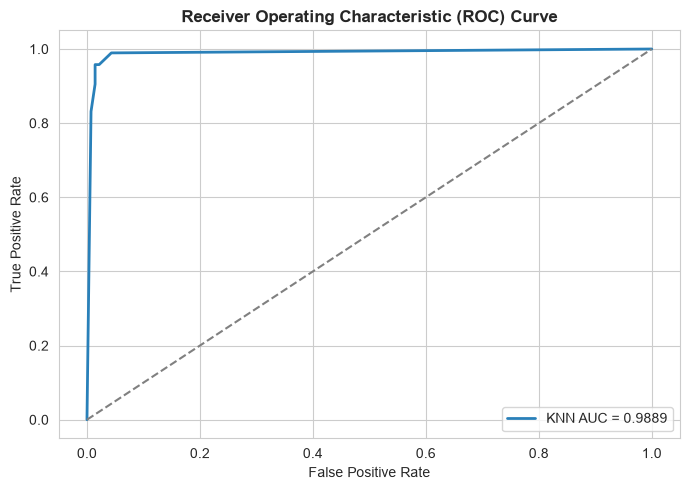

In [11]:
# ROC Curve & AUC Score
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#2980b9', lw=2, label=f'KNN AUC = {auc_score:.4f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'Nilai ROC-AUC Score: {auc_score:.4f}')


---
## 6. Simulasi Prediksi Pasien Baru


In [12]:
def prediksi_risiko(data_pasien: dict):
    # Konversi ke dataframe
    df_baru = pd.DataFrame([data_pasien])[feature_cols]
    
    # Standarisasi menggunakan scaler yang sudah di-fit
    df_scaled = scaler.transform(df_baru)
    
    # Prediksi
    pred = knn.predict(df_scaled)[0]
    prob_high = knn.predict_proba(df_scaled)[0, 1]
    prob_low = 1.0 - prob_high
    label = 'High Risk' if pred == 1 else 'Low Risk'
    
    print('=' * 50)
    print('HASIL PREDIKSI DATA PASIEN:')
    print('=' * 50)
    for k, v in data_pasien.items():
        print(f'  {k:25s}: {v}')
    print('-' * 50)
    print(f'  Probabilitas Low Risk   : {prob_low * 100:.1f}%')
    print(f'  Probabilitas High Risk  : {prob_high * 100:.1f}%')
    print(f'  Hasil Prediksi          : {label}')
    print('=' * 50)
    return label, prob_high


In [13]:
# Contoh 1: Data pasien dengan indikasi risiko tinggi
pasien_1 = {
    'Age': 35,
    'Systolic BP': 140.0,
    'Diastolic': 95.0,
    'BS': 13.0,
    'Body Temp': 98,
    'BMI': 31.0,
    'Previous Complications': 1,
    'Preexisting Diabetes': 1,
    'Gestational Diabetes': 1,
    'Mental Health': 0,
    'Heart Rate': 85.0
}

hasil_1 = prediksi_risiko(pasien_1)


HASIL PREDIKSI DATA PASIEN:
  Age                      : 35
  Systolic BP              : 140.0
  Diastolic                : 95.0
  BS                       : 13.0
  Body Temp                : 98
  BMI                      : 31.0
  Previous Complications   : 1
  Preexisting Diabetes     : 1
  Gestational Diabetes     : 1
  Mental Health            : 0
  Heart Rate               : 85.0
--------------------------------------------------
  Probabilitas Low Risk   : 0.0%
  Probabilitas High Risk  : 100.0%
  Hasil Prediksi          : High Risk


In [14]:
# Contoh 2: Data pasien dengan kondisi normal
pasien_2 = {
    'Age': 23,
    'Systolic BP': 110.0,
    'Diastolic': 70.0,
    'BS': 5.0,
    'Body Temp': 98,
    'BMI': 21.5,
    'Previous Complications': 0,
    'Preexisting Diabetes': 0,
    'Gestational Diabetes': 0,
    'Mental Health': 0,
    'Heart Rate': 72.0
}

hasil_2 = prediksi_risiko(pasien_2)


HASIL PREDIKSI DATA PASIEN:
  Age                      : 23
  Systolic BP              : 110.0
  Diastolic                : 70.0
  BS                       : 5.0
  Body Temp                : 98
  BMI                      : 21.5
  Previous Complications   : 0
  Preexisting Diabetes     : 0
  Gestational Diabetes     : 0
  Mental Health            : 0
  Heart Rate               : 72.0
--------------------------------------------------
  Probabilitas Low Risk   : 100.0%
  Probabilitas High Risk  : 0.0%
  Hasil Prediksi          : Low Risk
